# Outliers, transformations and a cleaning pipeline

*Session 4, block 2 · Course team · Licence: CC BY 4.0 (curated third-party parts keep their licence, named at each section)*

After this block you can detect and judge outliers in one variable (IQR rule, z-score, median absolute deviation) and in combinations of variables (Mahalanobis distance, classical and robust), apply suitable transformations (logarithm, Box–Cox, Yeo–Johnson, scaling), and combine every cleaning decision into a pipeline that writes a log, so that the cleaned table can be reproduced and defended.

All examples use the Berlin listings of Inside Airbnb (snapshot of 26 June 2026, CC BY 4.0), prepared with `uv run python case-study/prepare_airbnb.py`. Model-based outlier detection (Isolation Forest, local outlier factor) follows in Session 11.

## Teaching map

The **core path** fills the 45 minutes of theory. Subsections marked *(depth: self-study or if time allows)* go further; skip them in class and point students to them.

| Section | Core minutes | Core path | Depth subsections |
|---|---|---|---|
| 1 · Univariate outliers | 12 | three rules by hand and on price; minimum stays | frequency tables and the extremes; what to do with a flagged value |
| 2 · Multivariate outliers with the Mahalanobis distance | 9 | the idea, a hand calculation, classical against robust | the scikit-learn example; unusual prices for the number of guests |
| 3 · Transformations | 10 | log, Box–Cox, Yeo–Johnson and scalers on the listings | six distributions; every scaler side by side; why scaling matters; transforming the target |
| 4 · A documented cleaning pipeline | 5 | rule, rows, action, reason; `pipe` | preprocessing pipelines in scikit-learn |
| Worked example · the cleaned listings | 9 | twelve logged steps, validation, export | |
| **Total** | **45** | | |

```mermaid
flowchart LR
    RAW["listings.parquet"] --> S1["keys,<br/>placeholders"]
    S1 --> S2["flags: price missing,<br/>medium-term, no reviews"]
    S2 --> S3["impute bedrooms,<br/>indicators, licence status"]
    S3 --> S4["extreme prices, log price,<br/>Mahalanobis"]
    S4 --> V{"validate"}
    V -->|pass| OUT["cleaned table<br/>+ cleaning log"]
    V -->|fail| S1
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next we load the listings and the plotting library. `plt.rcParams` sets defaults for all figures of the notebook.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.spines.top": False, "axes.spines.right": False})
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
price = listings["price"].dropna()                     # EUR per night
print(len(listings), "listings,", len(price), "with a price")

12776 listings, 8441 with a price


## 1 · Univariate outliers (IQR rule, z-score, median absolute deviation)

An **outlier** is an observation that lies far from the bulk of the data. A **univariate** rule looks at one variable at a time. Extreme values matter because they move means, standard deviations, correlations and regression lines; but they are also often the interesting cases (the luxury flat, the hostel dormitory). So a flag is a **question, not a verdict**: a *data error* (typo, unit mix-up, placeholder) is corrected or removed; a *genuine extreme value* is kept and handled by the method.

Three rules are standard:

- **IQR rule (Tukey's fences).** Q1 and Q3 are the 25th and 75th percentiles; the **interquartile range** IQR = Q3 − Q1 is the width of the middle half of the data. Flag values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR. This is the rule behind the whiskers of a boxplot.
- **z-score.** z = (x − mean) / SD says how many standard deviations a value lies from the mean; |z| > 3 is a common cut-off.
- **Robust z-score with the median absolute deviation (MAD).** MAD = median(|x − median|), the typical distance from the median. z* = 0.6745·(x − median) / MAD; Iglewicz and Hoaglin (1993) suggest flagging |z*| > 3.5. The factor 0.6745 makes z* comparable with z for normally distributed data.

The z-score has a weakness called **masking**: the outliers inflate the mean and the SD that are used to find them, so they can hide themselves. Median, quartiles and MAD are **robust**: a few extreme values barely move them. Analogy: one billionaire moving into a village changes the average income a lot and the median income not at all.

A worked example by hand with the values 2, 3, 3, 4, 4, 5, 40:

- Q1 = 3, Q3 = 4.5, IQR = 1.5; upper fence 4.5 + 2.25 = 6.75, so 40 is flagged.
- mean = 8.7, SD = 13.8; z(40) = 2.3, so 40 is **not** flagged with |z| > 3 (masking).
- median = 4, MAD = median(2, 1, 1, 0, 0, 1, 36) = 1; z*(40) = 0.6745·36 = 24.3, so it is flagged.

**Predict**, then check: next we compute the three rules for these seven values. `Series.quantile([0.25, 0.75])` returns both quartiles; `.std()` in pandas divides by n − 1.

In [3]:
x = pd.Series([2, 3, 3, 4, 4, 5, 40])
q1, q3 = x.quantile([0.25, 0.75])
print("upper IQR fence:", q3 + 1.5 * (q3 - q1))
print("z of 40:", round((40 - x.mean()) / x.std(), 2))
mad = (x - x.median()).abs().median()
print("MAD:", mad, " robust z of 40:", round(0.6745 * (40 - x.median()) / mad, 1))

upper IQR fence: 6.75
z of 40: 2.26
MAD: 1.0  robust z of 40: 24.3


Next we write the three rules as one function that returns a Boolean column per rule, so that we can apply them to any variable. `pd.DataFrame({...})` builds a table from named Series.

In [4]:
def flag_rules(x: pd.Series) -> pd.DataFrame:
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    z = (x - x.mean()) / x.std()
    mad = (x - x.median()).abs().median()
    robust_z = 0.6745 * (x - x.median()) / mad
    return pd.DataFrame({"IQR": (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr),
                         "z": z.abs() > 3,
                         "MAD": robust_z.abs() > 3.5})

*Practice of this block: find outliers in price and minimum stay.* **Predict:** which rule flags the most prices, and which the fewest? Prices are strongly right-skewed, so we also apply the rules on the log scale. The mean of a Boolean column is the share of `True`.

In [5]:
print(price.describe().round(1).to_dict())
print("share flagged, raw scale:", flag_rules(price).mean().round(3).to_dict())
print("share flagged, log scale:", flag_rules(np.log10(price)).mean().round(3).to_dict())

{'count': 8441.0, 'mean': 160.7, 'std': 205.0, 'min': 2.7, '25%': 72.0, '50%': 130.7, '75%': 207.0, 'max': 10025.0}
share flagged, raw scale: {'IQR': 0.043, 'z': 0.006, 'MAD': 0.027}
share flagged, log scale: {'IQR': 0.037, 'z': 0.003, 'MAD': 0.012}


![Price per night with the fences of the IQR rule, the z-score and the MAD rule on the raw and on the log scale](../figures/univariate-outliers.png)

On the raw scale the IQR rule flags about 4 % of the prices, all of them high: a consequence of the skewed distribution, not of errors. The z-score flags only 0.6 %, because the extreme prices inflate the standard deviation to about €205 (masking). On the log scale the picture turns around: the rules flag both tails, and the histogram has a **second peak** around €20 a night.

Look at who is there before flagging anything. Next we put the priced listings into bands of minimum stay. `pd.cut` with `labels` names the bands; `groupby([...]).agg(["size", "median"])` counts and summarises per group.

In [6]:
priced = listings[listings["price"].notna()].copy()
priced["stay"] = pd.cut(priced["minimum_nights"], [0, 6, 27, 91, 10_000], labels=["1-6 nights", "7-27", "28-91", "92+"])
print(priced[priced["room_type"].eq("Entire home/apt")].groupby("stay", observed=True)["price"].agg(["size", "median"]).round(1))
print("share of prices under 15 EUR with a minimum stay of 28+ nights:",
      round((priced.loc[priced["price"] < 15, "minimum_nights"] >= 28).mean(), 2))

            size  median
stay                    
1-6 nights  4415   188.0
7-27         273   137.4
28-91        203    69.3
92+         1245    22.8
share of prices under 15 EUR with a minimum stay of 28+ nights: 0.98


The very low prices belong almost entirely to listings with a minimum stay of at least 28 nights. An entire flat for a few tens of euros a night is far below any holiday price in Berlin, so the price field of these **medium-term** listings is not comparable with short-stay prices; we cannot tell from the data how it was computed. That is not an outlier to delete one by one, it is a **different population**. Sessions 5 and 6 analyse prices of short-stay listings (minimum stay below 28 nights) and say so.

At the top end, next we look at the six highest prices. `nlargest(n, column)` returns the rows with the largest values.

In [7]:
listings.nlargest(6, "price")[["price", "property_type", "accommodates", "minimum_nights", "number_of_reviews"]]

,price,property_type,accommodates,minimum_nights,number_of_reviews
8434,10025.0,Entire loft,7,2.0,68
12710,7999.2,Entire home,5,1.0,0
9515,4458.0,Houseboat,16,1.0,1
517,2956.0,Entire loft,15,1.0,17
10772,2296.0,Entire home,16,1.0,1
11253,2270.4,Houseboat,12,1.0,2


Prices of €8,000 and more a night for a house for five and a loft for seven are implausible for their size: typing errors, or deliberately high prices that keep a listing from being booked. The data cannot tell which. Others are genuine: houseboats for 12 to 16 guests. Flag them, keep them out of averages, and use robust methods (Session 6).

**Minimum stay.** **Predict:** what will the MAD rule do with this variable? Next we look at its quantiles and at the share of the most common long value.

In [8]:
nights = listings["minimum_nights"].dropna()
print(nights.quantile([0.5, 0.75, 0.9, 0.99]).to_dict(), "max", nights.max())
print("share with exactly 92 nights:", round((nights == 92).mean(), 3))
print("share flagged:", flag_rules(nights).mean().round(3).to_dict())

{0.5: 3.0, 0.75: 92.0, 0.9: 92.0, 0.99: 180.0} max 1125.0
share with exactly 92 nights: 0.296
share flagged: {'IQR': 0.003, 'z': 0.003, 'MAD': 0.366}


The minimum stay has **two clusters**: one to three nights, and exactly 92 nights. With a median of 3 and a MAD of 2 nights, every 92-night listing gets a huge robust z, so the MAD rule flags the whole medium-term cluster, more than a third of all listings. Every rule that assumes one centre misleads here. A **domain rule** is clearer: "a minimum stay of 28 nights or more is a medium-term listing" (Berlin restricts short-term rentals, and many hosts offer medium-term stays instead). The ten minimum stays above a year are flagged separately, as in block 1.

> **Note.** With large samples, |z| > 3 is not rare even for perfectly normal data: about 0.27 % of normal values exceed it, so among 300,000 values about 810 would be flagged by chance. A flag rate tells you about the shape of the distribution as much as about errors.

### Frequency tables and the extremes *(depth: self-study or if time allows)*

Before any rule, look at the values themselves. A **frequency table** lists each value with the number of times it occurs (`value_counts()`); sorted by value (`sort_index()`), its first and last rows are the smallest and largest values. Reading them with domain knowledge separates recording errors from rare but real values. Downey's *Think Stats* (chapter 2) does exactly this with pregnancy lengths in a US survey; the extra linked below follows it step by step. Next we do the same for the number of guests and the number of bedrooms.

In [9]:
print("accommodates:", listings["accommodates"].value_counts().sort_index().to_dict())
print("bedrooms (largest):", listings["bedrooms"].value_counts().sort_index().tail(5).to_dict())
print("bedrooms = 0:", listings["bedrooms"].eq(0).sum(), "of which studios or rooms:",
      listings.loc[listings["bedrooms"].eq(0), "property_type"].str.contains("studio|room", case=False).sum())

accommodates: {1: 1123, 2: 5880, 3: 1426, 4: 2323, 5: 531, 6: 837, 7: 143, 8: 226, 9: 72, 10: 74, 11: 32, 12: 49, 13: 11, 14: 17, 15: 9, 16: 23}
bedrooms (largest): {7.0: 3, 8.0: 2, 9.0: 2, 12.0: 1, 14.0: 1}
bedrooms = 0: 4 of which studios or rooms: 4


Sixteen guests is the platform's maximum, so the right end of `accommodates` is a cap, not an error. Zero bedrooms looks impossible, but the four such listings are all studios or rooms: a description, not an error. A frequency table also shows **heaping**: values that occur much more often than their neighbours because of a default or a habit (the 92-night minimum stay, the 1,125-night maximum). A histogram is the picture of a frequency table; on prices, next we compare the full histogram with the same data on a log axis.

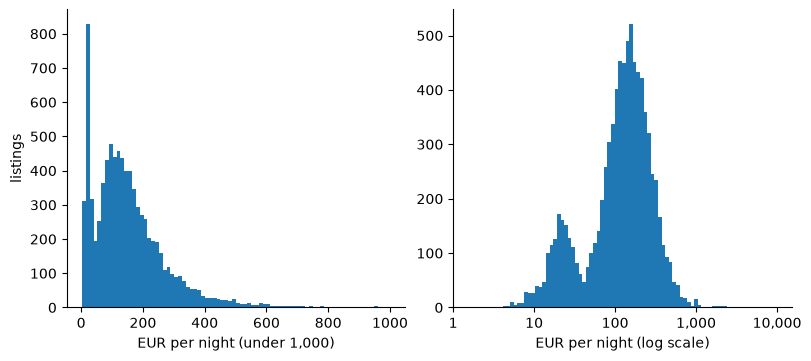

In [10]:
fig, axes = plt.subplots(1, 2, layout="constrained")
axes[0].hist(price[price < 1000], bins=80)
axes[0].set(xlabel="EUR per night (under 1,000)", ylabel="listings")
axes[1].hist(np.log10(price), bins=80)
axes[1].set_xticks([0, 1, 2, 3, 4], ["1", "10", "100", "1,000", "10,000"])
axes[1].set(xlabel="EUR per night (log scale)")
plt.show()

> 📖 **Read more:** [extras/06-distributions-and-outliers.ipynb](extras/06-distributions-and-outliers.ipynb) (Downey, *Think Stats*, 3rd ed., chapter 2; text CC BY-NC-SA, read only): frequency tables, histograms and a close look at the extremes of survey data, then comparing two groups with an effect size. Needs `empiricaldist` and `statadict` (see the extras README).

### What to do with a flagged value *(depth: self-study or if time allows)*

*Adapted from [Data Preparation](https://github.com/microsoft/Data-Science-For-Beginners/blob/main/2-Working-With-Data/08-data-preparation/notebook.ipynb) (Microsoft, Data Science for Beginners, MIT).*

Once a value is flagged and inspected, there are five options:

1. **Remove** the row, if the value is an error that cannot be corrected and the row is useless without it.
2. **Correct** it, if the rule is known (a price typed in cents, a unit mix-up).
3. **Set to missing** (`NaN`) and treat it like any missing value (block 1), if the value is impossible but the rest of the row is useful. The 2,147,483,647-night maximum stay is the example.
4. **Cap** (also called *winsorising*): replace values beyond a limit by the limit, so that they still count as "very large" but no longer dominate a mean. `Series.clip(lower, upper)` does this.
5. **Keep**, if the value is genuine, and choose a method that copes with it (a log scale, the median, robust regression) or add a flag column.

Next we see what capping at the 99th percentile does to the mean price. **Predict** first: will the mean move by more or less than €5?

In [11]:
cap = price.quantile(0.99)
print("99th percentile:", round(cap, 1))
print("mean raw:", round(price.mean(), 1), " mean capped:", round(price.clip(upper=cap).mean(), 1),
      " median:", round(price.median(), 1))
q1, q3 = price.quantile([0.25, 0.75])
above = listings.loc[price.index][price > q3 + 1.5 * (q3 - q1)]
print("above the IQR fence:", len(above), "listings; share with 6+ guests:", round(above["accommodates"].ge(6).mean(), 2))

99th percentile: 632.3


mean raw: 160.7  mean capped: 154.8  median: 130.7


above the IQR fence: 362 listings; share with 6+ guests: 0.7


Capping 1 % of the values moves the mean noticeably, while the median does not move at all. Whatever you choose, the decision and the number of rows affected go into the cleaning log (section 4).

> **Note.** Do not delete outliers automatically. Removing genuine extreme values makes the data look tidier and the conclusions wrong: about seven in ten listings above the IQR fence sleep six or more guests (last line above), so deleting them removes much of the market for families and groups.

## 2 · Multivariate outliers with the Mahalanobis distance

A **multivariate outlier** is unusual in the *combination* of its values, not necessarily in any single one. A height of 192 cm is not unusual, nor is a weight of 55 kg; a person who is both is.

The **Mahalanobis distance** measures how far a point lies from the centre of the data in units that take into account the spread of each variable and the correlation between them (the **covariance matrix**):

d(x) = √((x − μ)ᵀ Σ⁻¹ (x − μ))

In words: subtract the centre μ, then "divide" by the covariance Σ. If the variables are uncorrelated and standardised, this is the ordinary distance in standard deviations. If they are correlated, moving *along* the correlation is cheap and moving *against* it is expensive: the points of equal distance form an **ellipse** aligned with the data. For roughly normal data with p variables, d² follows a **chi-square distribution** with p degrees of freedom, which gives a cut-off: for p = 2 and the 99.9 % quantile, d² > 13.8.

A hand calculation with two standardised variables: the point (2, 2) has Euclidean distance √8 = 2.83. If the variables have correlation 0.8, the same point lies *along* the correlation and its Mahalanobis distance is √(8 / 1.8) = 2.11; the point (2, −2), *against* the correlation, has √(8 / 0.2) = 6.32.

**Predict**, then check with NumPy: `np.linalg.inv` inverts the covariance matrix, and `@` is matrix multiplication.

In [12]:
cov = np.array([[1.0, 0.8], [0.8, 1.0]])
inv = np.linalg.inv(cov)
for point in ([2, 2], [2, -2]):
    p = np.array(point)
    print(point, "Euclidean", round(float(np.sqrt(p @ p)), 2), " Mahalanobis", round(float(np.sqrt(p @ inv @ p)), 2))

[2, 2] Euclidean 2.83  Mahalanobis 2.11
[2, -2] Euclidean 2.83  Mahalanobis 6.32


**Masking again.** The mean and covariance are themselves distorted by outliers. The **minimum covariance determinant** estimator (MCD, `sklearn.covariance.MinCovDet`, Rousseeuw 1984) estimates them from the most concentrated subset of about half of the data, so that a group of outliers cannot pull the centre and stretch the ellipse towards itself.

Next we simulate 500 people with correlated height and weight, add the tall, light person and a contaminating group of 25 short, heavy records (for example a batch with swapped columns), and compare the classical estimate (`EmpiricalCovariance`) with MCD. `.mahalanobis(X)` returns the **squared** distances; `scipy.stats.chi2.ppf(0.999, df=2)` is the cut-off.

In [13]:
from scipy.stats import chi2
from sklearn.covariance import EmpiricalCovariance, MinCovDet

rng = np.random.default_rng(0)
height = rng.normal(172, 9, 500)
weight = 0.9 * height - 85 + rng.normal(0, 6, 500)
X = np.vstack([np.column_stack([height, weight]), [[192, 55]],
               np.column_stack([rng.normal(150, 3, 25), rng.normal(95, 4, 25)])])
print("z of row 500:", ((X[500] - X.mean(axis=0)) / X.std(axis=0)).round(1))
cut = chi2.ppf(0.999, df=2)
for est in [EmpiricalCovariance().fit(X), MinCovDet(random_state=0).fit(X)]:
    d2 = est.mahalanobis(X)
    print(f"{type(est).__name__:19s} d(row 500) = {np.sqrt(d2[500]):.1f}  group flagged: {(d2[501:] > cut).sum()}/25")

z of row 500: [ 2.1 -1.4]
EmpiricalCovariance d(row 500) = 3.2  group flagged: 17/25
MinCovDet           d(row 500) = 6.4  group flagged: 25/25


![Classical and robust Mahalanobis ellipses for height and weight with a single outlier and a contaminating group](../figures/mahalanobis-ellipses.png)

Each variable alone has |z| < 3 for the tall, light person. With the classical estimate, the contaminating group pulls the centre and inflates the covariance: the person is not flagged and part of the group escapes. With MCD, the person and the whole group are flagged. The figure shows the two ellipses (`figures/make_figures.py` draws it from the same simulation).

> **Note.** The distance assumes one roughly elliptical cloud. With strongly skewed variables, transform them first (section 3); with several clusters or many identical values, use the model-based methods of Session 11. MCD also needs a covariance matrix that is not singular: a variable that is constant in more than half of the rows (for example `bedrooms` among entire homes, mostly exactly one) makes it fail.

### The scikit-learn example: contaminated data *(depth: self-study or if time allows)*

*Adapted from [Robust covariance estimation and Mahalanobis distances relevance](https://scikit-learn.org/stable/auto_examples/covariance/plot_mahalanobis_distances.html) (scikit-learn developers, BSD-3-Clause).*

The scikit-learn example makes the same point with a cleaner design. 125 points come from a normal distribution in which feature 1 has standard deviation 2 and feature 2 has standard deviation 1. Then 25 of them are replaced by outliers whose feature 2 has standard deviation 7. The standard, **maximum likelihood** estimate of the covariance (MLE, the ordinary sample covariance) is very sensitive to such points; MCD is a **high-breakdown** estimator: it still works when up to (n − p − 1)/2 of the points are outliers, because it looks for the (n + p + 1)/2 points whose covariance has the smallest determinant (the "tightest" subset) and estimates from those. Next we generate the data exactly as in the source.

In [14]:
np.random.seed(7)
n_samples, n_outliers, n_features = 125, 25, 2
gen_cov = np.eye(n_features)
gen_cov[0, 0] = 2.0
Xs = np.dot(np.random.randn(n_samples, n_features), gen_cov)
outliers_cov = np.eye(n_features)
outliers_cov[np.arange(1, n_features), np.arange(1, n_features)] = 7.0
Xs[-n_outliers:] = np.dot(np.random.randn(n_outliers, n_features), outliers_cov)

**Predict:** which estimate will report the larger variance of feature 2? `covariance_` holds the estimated matrix.

In [15]:
robust_cov = MinCovDet().fit(Xs)
emp_cov = EmpiricalCovariance().fit(Xs)
print("MCD (robust):\n", robust_cov.covariance_.round(2), "\nMLE:\n", emp_cov.covariance_.round(2))

MCD (robust):
 [[ 3.6  -0.08]
 [-0.08  1.52]] 
MLE:
 [[ 3.24 -0.25]
 [-0.25  7.52]]


The MLE variance of feature 2 is inflated by the outliers (about 7.5); the MCD estimate is much closer to the true values (4 for feature 1, 1 for feature 2). Next we draw the contours of equal Mahalanobis distance for both estimates over a grid. `np.meshgrid` builds the grid; `plt.contour` draws lines of equal value.

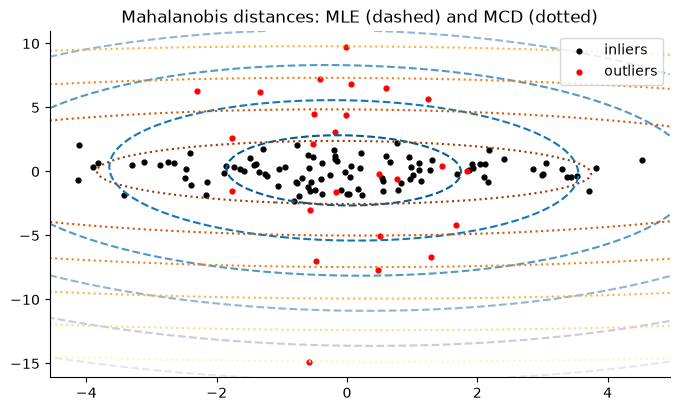

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(Xs[:-n_outliers, 0], Xs[:-n_outliers, 1], color="black", s=12, label="inliers")
ax.scatter(Xs[-n_outliers:, 0], Xs[-n_outliers:, 1], color="red", s=12, label="outliers")
xx, yy = np.meshgrid(np.linspace(*ax.get_xlim(), 100), np.linspace(*ax.get_ylim(), 100))
zz = np.c_[xx.ravel(), yy.ravel()]
ax.contour(xx, yy, np.sqrt(emp_cov.mahalanobis(zz)).reshape(xx.shape), cmap=plt.cm.PuBu_r, linestyles="dashed")
ax.contour(xx, yy, np.sqrt(robust_cov.mahalanobis(zz)).reshape(xx.shape), cmap=plt.cm.YlOrBr_r, linestyles="dotted")
ax.set_title("Mahalanobis distances: MLE (dashed) and MCD (dotted)")
ax.legend(loc="upper right")
plt.show()

The robust (dotted) contours fit the inliers tightly; the MLE (dashed) contours are stretched upwards by the outliers. Finally the source compares the distances of inliers and outliers with boxplots. The cube root of the distance is roughly normal (Wilson and Hilferty, 1931), which makes the boxplots easier to read.

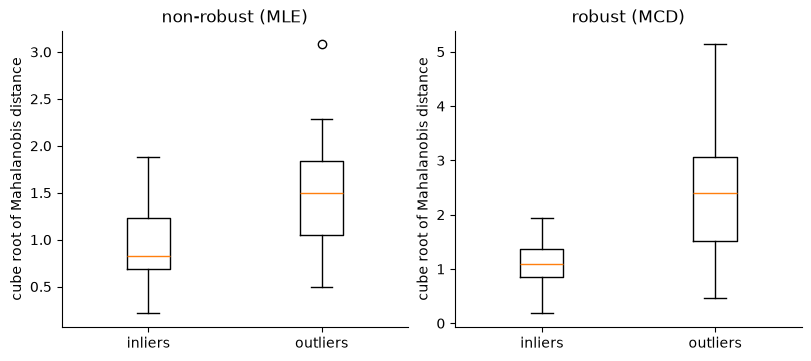

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), layout="constrained")
for ax, est, title in [(axes[0], emp_cov, "non-robust (MLE)"), (axes[1], robust_cov, "robust (MCD)")]:
    d = est.mahalanobis(Xs - est.location_) ** 0.33
    ax.boxplot([d[:-n_outliers], d[-n_outliers:]], widths=0.25)
    ax.set_xticks([1, 2], ["inliers", "outliers"])
    ax.set(title=title, ylabel="cube root of Mahalanobis distance")
plt.show()

With the robust estimate, the outliers are clearly separated from the inliers; with MLE they overlap. Applications include outlier detection, ranking observations by how typical they are, and clustering.

> 📖 **Read more:** [extras/07-mahalanobis-and-robust-covariance.ipynb](extras/07-mahalanobis-and-robust-covariance.ipynb) (scikit-learn gallery): the original example.

### Unusual prices for the number of guests *(depth: self-study or if time allows)*

On the listings, a price is unusual mainly *for its size*: €400 is normal for a flat for eight and odd for a room for one. Next we compute the robust distance on log price and log number of guests for the short-stay listings with a price (both variables log-transformed first, as the note above advises).

In [18]:
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)]
Z = np.column_stack([np.log(short["price"]), np.log(short["accommodates"])])
cut = chi2.ppf(0.999, df=2)
flags = {name: est.fit(Z).mahalanobis(Z) > cut for name, est in
         [("classical", EmpiricalCovariance()), ("robust (MCD)", MinCovDet(random_state=0))]}
print({name: int(f.sum()) for name, f in flags.items()}, "of", len(short))
short.loc[flags["robust (MCD)"], "room_type"].value_counts()

{'classical': 62, 'robust (MCD)': 93} of 6701


room_type
Entire home/apt    43
Shared room        34
Private room       16
Name: count, dtype: int64

The robust estimate flags more listings than the classical one. Next we plot them. `ax.scatter(..., alpha=0.3)` makes points transparent so that dense areas show.

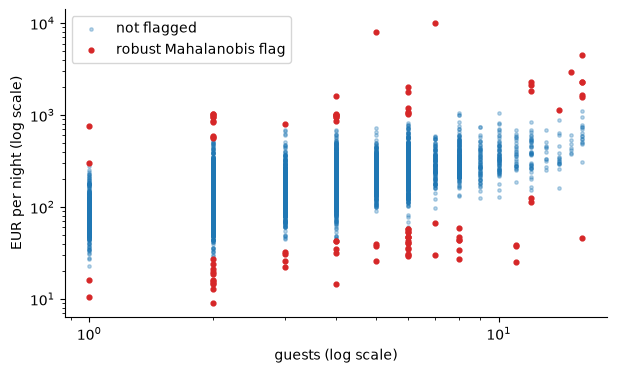

In [19]:
fig, ax = plt.subplots(figsize=(7, 4))
f = flags["robust (MCD)"]
ax.scatter(short["accommodates"][~f], short["price"][~f], s=6, alpha=0.3, label="not flagged")
ax.scatter(short["accommodates"][f], short["price"][f], s=12, color="tab:red", label="robust Mahalanobis flag")
ax.set(xscale="log", yscale="log", xlabel="guests (log scale)", ylabel="EUR per night (log scale)")
ax.legend()
plt.show()

The flags are of two kinds: entire homes whose price is implausible for their size (very high for few guests), and shared rooms for many guests at a low price, which are hostel dormitories and perfectly genuine. A multivariate flag is a question, not a verdict. The worked example adds this flag to the cleaned table.

## 3 · Transformations (logarithm, Box–Cox, Yeo–Johnson, scaling)

A **transformation** applies the same function to every value of a variable. Two goals are common: making a skewed distribution more symmetric, and bringing variables to comparable scales. Many methods work better, or only as intended, with roughly symmetric variables on similar scales: linear regression assumes errors of constant spread (Session 6), distance-based methods treat one unit of each variable as equally important, and PCA (Session 11) is dominated by the variable with the largest variance. Transforming often turns "outliers" into ordinary tail values.

- **Logarithm.** log(x) turns multiplication into addition: 10, 100, 1,000 become equally spaced. It compresses long right tails (prices, incomes, counts of reviews). It needs x > 0; for counts with zeros, log(1 + x) (`np.log1p`) is used.
- **Box–Cox** (Box and Cox, 1964) is a family of power transformations with a parameter λ, estimated from the data so that the result is as close to normal as possible: y = (x^λ − 1) / λ for λ ≠ 0, and y = log(x) for λ = 0. λ = 1 leaves the shape unchanged, λ = 0.5 is close to a square root, λ = 0 is the logarithm. It needs x > 0.
- **Yeo–Johnson** (Yeo and Johnson, 2000) extends the idea to zero and negative values.
- **Scaling** changes the unit but not the shape:

| Scaler | Formula | Use |
|---|---|---|
| `StandardScaler` | (x − mean) / SD | default for linear models, PCA, k-nearest neighbours |
| `MinMaxScaler` | (x − min) / (max − min) | bounded inputs |
| `RobustScaler` | (x − median) / IQR | data with outliers |

A worked example by hand: nightly prices of €50, €500 and €5,000. Their mean is €1,850, dominated by the most expensive. Their base-10 logarithms are 1.7, 2.7 and 3.7, with mean 2.7, corresponding to a typical price of 10^2.7 = €500, the **geometric mean**.

```mermaid
flowchart TD
    A{"Goal?"} -->|"common scale"| SC{"Outliers?"}
    SC -->|no| STD["StandardScaler"]
    SC -->|yes| ROB["RobustScaler"]
    A -->|"less skew"| V{"Values?"}
    V -->|"all > 0"| L["log, or Box–Cox<br/>(estimates λ)"]
    V -->|"zeros or negative"| Y["log1p for counts,<br/>or Yeo–Johnson"]
```

**Skewness** measures asymmetry: 0 for a symmetric distribution, positive for a long right tail. **Predict** the λ that Box–Cox will choose for the price: closer to 1 (no change) or to 0 (logarithm)? `scipy.stats.boxcox` returns the transformed values and λ.

In [20]:
from scipy.stats import boxcox, skew

transformed, lam = boxcox(price)
print("lambda", round(lam, 2))
print("skewness raw", round(skew(price), 1), " log", round(skew(np.log(price)), 2), " Box-Cox", round(skew(transformed), 2))

lambda 0.23
skewness raw 22.5  log -0.68  Box-Cox 0.04


scikit-learn's `PowerTransformer` does the same and **stores** λ, so that new data are transformed with the same λ; by default it also standardises the result. For the number of reviews, a fifth of which are zero, Box–Cox is impossible; Yeo–Johnson and `log1p` work.

In [21]:
from sklearn.preprocessing import PowerTransformer

print("Box-Cox lambda:", PowerTransformer(method="box-cox").fit(price.to_frame()).lambdas_.round(2))
reviews = listings[["number_of_reviews"]]
yj = PowerTransformer(method="yeo-johnson").fit(reviews)
print("reviews skewness raw", round(skew(reviews["number_of_reviews"]), 1),
      " log1p", round(skew(np.log1p(reviews["number_of_reviews"])), 2), " Yeo-Johnson", round(skew(yj.transform(reviews).ravel()), 2))

Box-Cox lambda: [0.23]
reviews skewness raw 5.4  log1p 0.17  Yeo-Johnson 0.04


![Price per night before and after the Box–Cox transformation, with normal Q–Q plots](../figures/box-cox-before-after.png)

The plain logarithm over-corrects the price (the skewness turns negative); Box–Cox with λ ≈ 0.23, between the logarithm and a fourth root, brings it close to zero. The figure shows why a skewness near zero is not the end of the story: the transformed histogram has **two peaks**, and the **Q–Q plot** (sample quantiles against the quantiles of a normal distribution; a straight line means normal) bends where they meet. The smaller peak is the medium-term listings of section 1, a different population that no transformation can merge with the rest.

**Scalers.** Next we scale three columns. **Predict** the standard deviations after `StandardScaler`. `RobustScaler().scale_` holds the IQR used for each column.

In [22]:
from sklearn.preprocessing import RobustScaler, StandardScaler

X3 = listings.loc[price.index, ["price", "accommodates", "number_of_reviews"]]
print(StandardScaler().fit_transform(X3).std(axis=0).round(2))
print(RobustScaler().fit(X3).scale_)

[1. 1. 1.]
[135.   2.  80.]


> **Note.** Fit transformations (λ, mean, SD, median, IQR) on the training data and apply them unchanged to the test data; estimating them on all data is a mild form of leakage (Session 7). And translate results back for the reader: exp(mean(log price)) is the geometric mean, not the average price. Say which one you report.

### Box–Cox and Yeo–Johnson on six distributions *(depth: self-study or if time allows)*

*Adapted from [Map data to a normal distribution](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_map_data_to_normal.html) (scikit-learn developers, BSD-3-Clause).*

The power transforms succeed on some distributions and fail on others, which is why you should always look at the data before and after. The source generates 1,000 values from each of six distributions (lognormal, chi-squared, Weibull, normal, uniform and bimodal), fits each transform on one half and applies it to the other half. For comparison it adds the **`QuantileTransformer`**, which maps the ranks of the values onto a normal distribution. It can force any shape into a bell curve when there are thousands of values, but it is **non-parametric** (no λ to report), harder to interpret, and prone to overfitting on small datasets (fewer than a few hundred values); there the power transforms are recommended. Next we generate the six samples.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer

rng = np.random.RandomState(304)
size = (1000, 1)
distributions = {"Lognormal": rng.lognormal(size=size), "Chi-squared": rng.chisquare(df=3, size=size),
                 "Weibull": rng.weibull(a=50, size=size), "Gaussian": rng.normal(loc=100, size=size),
                 "Uniform": rng.uniform(low=0, high=1, size=size),
                 "Bimodal": np.concatenate([rng.normal(loc=100, size=size), rng.normal(loc=105, size=size)])}

Next we transform each sample three ways and draw a grid: one row per distribution, the original in the first column. `bc.lambdas_[0]` is the estimated λ.

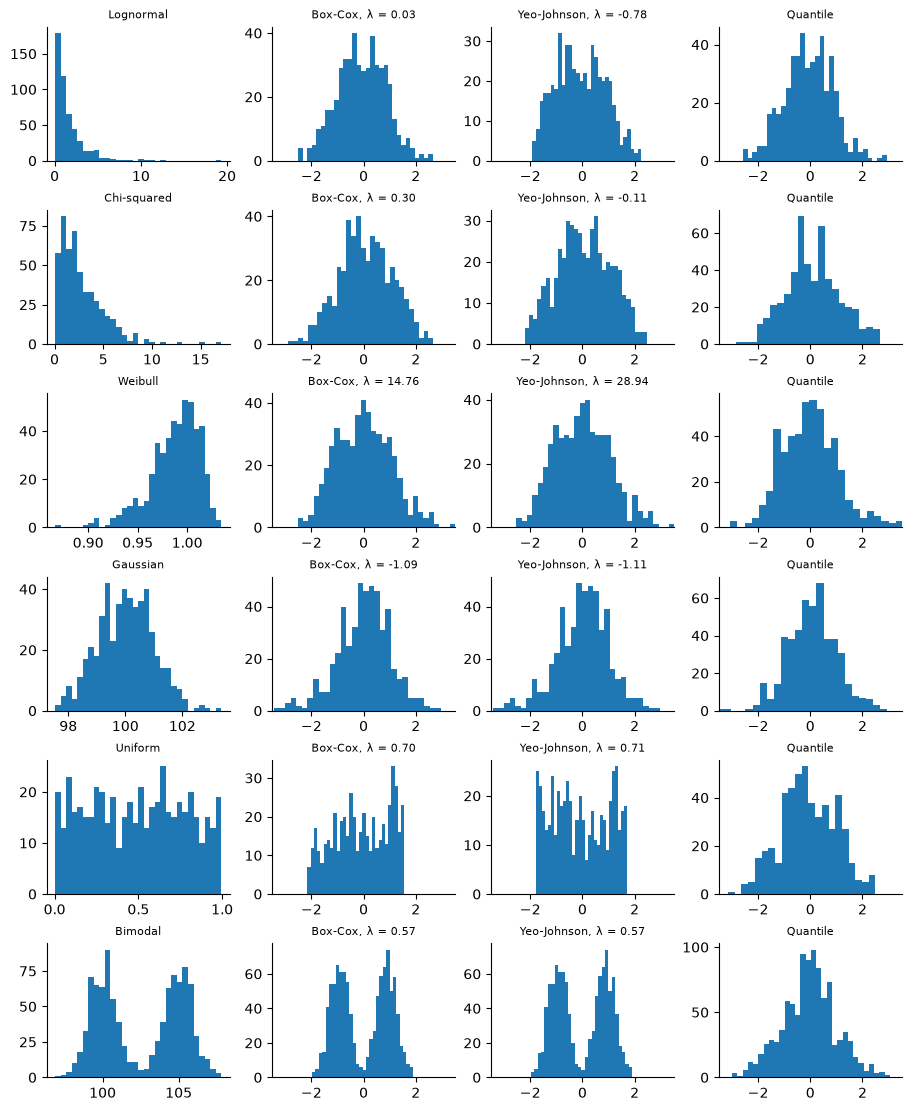

In [24]:
methods = {"Box-Cox": PowerTransformer(method="box-cox"), "Yeo-Johnson": PowerTransformer(method="yeo-johnson"),
           "Quantile": QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=0)}
fig, axes = plt.subplots(6, 4, figsize=(9, 11), layout="constrained")
for row, (name, Xd) in zip(axes, distributions.items()):
    X_train, X_test = train_test_split(Xd, test_size=0.5, random_state=0)
    row[0].hist(X_train, bins=30)
    row[0].set_title(name, fontsize=8)
    for ax, (m, tr) in zip(row[1:], methods.items()):
        ax.hist(tr.fit(X_train).transform(X_test), bins=30)
        lam_txt = f", λ = {tr.lambdas_[0]:.2f}" if hasattr(tr, "lambdas_") else ""
        ax.set_title(f"{m}{lam_txt}", fontsize=8)
        ax.set_xlim(-3.5, 3.5)
plt.show()

Lognormal and chi-squared become close to normal; Box–Cox does slightly better than Yeo–Johnson on them, but it cannot handle negative values. The Weibull sample is skewed to the left, and the power transforms fix it partly. Uniform and bimodal shapes stay non-normal under both power transforms; only the quantile transform forces them into a bell, and for the bimodal sample that hides the two groups, which is information. The same is true of the Airbnb prices.

> 📖 **Read more:** [extras/09-box-cox-and-yeo-johnson.ipynb](extras/09-box-cox-and-yeo-johnson.ipynb) (scikit-learn gallery): the original example.

### Every scaler side by side *(depth: self-study or if time allows)*

*Adapted from [Compare the effect of different scalers on data with outliers](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html) (scikit-learn developers, BSD-3-Clause). The California housing data of the source are replaced by the listings.*

Two listing variables have very different scales and long tails: the price (up to €10,025) and the number of reviews (up to several thousand). Such variables are hard to plot and can degrade many learning methods; unscaled data can also slow down or prevent the convergence of gradient-based estimators. Many estimators assume that each feature takes values close to zero and that all features vary on comparable scales. Tree-based models are a notable exception: they are insensitive to monotone rescaling.

The scalers are **linear** (affine) and differ in how they estimate the shift and the scale. `QuantileTransformer` and `PowerTransformer` are **non-linear**. The `Normalizer` is different again: it rescales each **row** (each listing) to length 1, not each column. Next we apply all of them to the two columns and summarise where the middle 98 % of each transformed column lies. `np.percentile(a, [1, 99], axis=0)` gives the 1st and 99th percentile per column.

In [25]:
from sklearn.preprocessing import MaxAbsScaler, MinMaxScaler, Normalizer

X2 = listings.loc[price.index, ["price", "number_of_reviews"]].to_numpy(dtype=float)
transforms = {"unscaled": None, "StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(),
              "MaxAbsScaler": MaxAbsScaler(), "RobustScaler": RobustScaler(),
              "PowerTransformer (Yeo-Johnson)": PowerTransformer(),
              "QuantileTransformer (uniform)": QuantileTransformer(random_state=0),
              "QuantileTransformer (normal)": QuantileTransformer(output_distribution="normal", random_state=0),
              "Normalizer (per row)": Normalizer()}
scaled = {name: X2 if t is None else t.fit_transform(X2) for name, t in transforms.items()}
pd.DataFrame({name: [f"{lo:.2f} to {hi:.2f}" for lo, hi in np.percentile(v, [1, 99], axis=0).T]
              for name, v in scaled.items()}, index=["price", "reviews"]).T

,price,reviews
unscaled,9.21 to 632.30,0.00 to 544.80
StandardScaler,-0.74 to 2.30,-0.56 to 3.74
MinMaxScaler,0.00 to 0.06,0.00 to 0.19
MaxAbsScaler,0.00 to 0.06,0.00 to 0.19
RobustScaler,-0.90 to 3.72,-0.25 to 6.56
PowerTransformer (Yeo-Johnson),-2.13 to 2.23,-1.48 to 1.87
QuantileTransformer (uniform),0.01 to 0.99,0.00 to 0.99
QuantileTransformer (normal),-2.33 to 2.33,-5.20 to 2.33
Normalizer (per row),0.15 to 1.00,0.00 to 0.99


How to read the table, scaler by scaler (following the source):

- **StandardScaler** removes the mean and divides by the SD. Because the extreme values inflate the SD differently in each column, the bulk of the data ends up in ranges of different width: it cannot guarantee balanced scales when there are outliers.
- **MinMaxScaler** maps the full range to [0, 1], and the few extreme values squeeze all ordinary values into a narrow band near 0.
- **MaxAbsScaler** divides by the largest absolute value; on positive data it behaves like `MinMaxScaler` and suffers in the same way.
- **RobustScaler** centres on the median and divides by the IQR, statistics that a few extreme values do not move: adding or removing outliers barely changes the transformation. The long tails themselves remain; if you want them clipped, you need a non-linear transformation.
- **PowerTransformer** (Yeo–Johnson by default, followed by standardisation) reduces the skew; most values lie within about ±2.
- **QuantileTransformer** maps the ranks to a uniform or normal distribution. Outliers become indistinguishable from the largest ordinary values: it collapses them to the boundary, which can create **saturation** at the extremes. Ties are a problem too: a fifth of the listings have 0 reviews, and the normal output puts all of them on one far-out value.
- **Normalizer** puts every listing on the unit circle; with two positive columns, all points lie in the positive quadrant. It is used for text and other data where only the *direction* of a row matters.

Next we draw four of them as scatter plots to see the shapes.

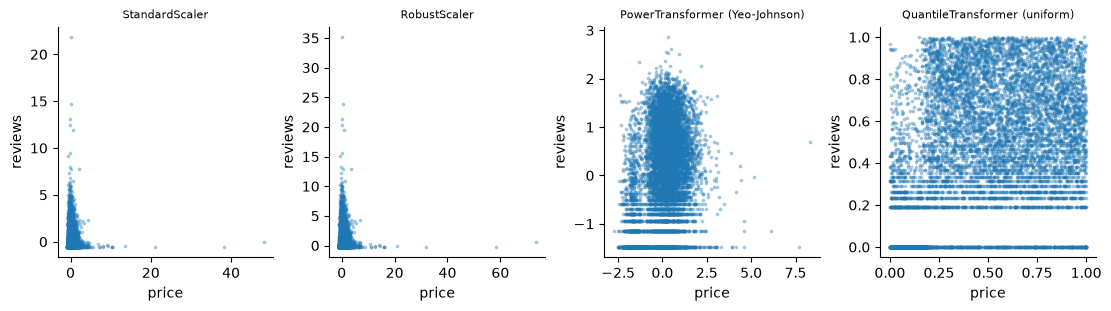

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3), layout="constrained")
for ax, name in zip(axes, ["StandardScaler", "RobustScaler", "PowerTransformer (Yeo-Johnson)", "QuantileTransformer (uniform)"]):
    v = scaled[name]
    ax.scatter(v[:, 0], v[:, 1], s=3, alpha=0.3)
    ax.set_title(name, fontsize=8)
    ax.set(xlabel="price", ylabel="reviews")
plt.show()

> 📖 **Read more:** [extras/08-scalers-and-transformers.ipynb](extras/08-scalers-and-transformers.ipynb) (scikit-learn gallery): the original example with marginal histograms and zoomed views without the outliers.

### Why scaling matters: k-nearest neighbours and PCA *(depth: self-study or if time allows)*

*Adapted from [Importance of Feature Scaling](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html) (scikit-learn developers, BSD-3-Clause).*

Standardisation (also called z-score normalisation) is an important step for many learning methods, for different reasons: it eases the convergence of some models (an unpenalised logistic regression), and it creates a *completely different model* for others (k-nearest neighbours, PCA). The source uses the **wine dataset** shipped with scikit-learn: 178 wines, 13 chemical measurements on very different scales (proline varies between about 300 and 1,700, hue between about 0.5 and 1.7). Next we load it.

In [27]:
from sklearn.datasets import load_wine

X_wine, y_wine = load_wine(return_X_y=True, as_frame=True)
X_wine[["proline", "hue", "alcohol"]].describe().loc[["min", "max", "std"]].round(2)

,proline,hue,alcohol
min,278.00,0.48,11.03
max,1680.00,1.71,14.83
std,314.91,0.23,0.81


**k-nearest neighbours** classifies a wine by the majority class of its nearest wines. Distances are dominated by the variable with the largest numbers. **Predict** how much scaling changes the cross-validated accuracy on the two features proline and hue. `make_pipeline(StandardScaler(), model)` scales inside each fold.

In [28]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

two = X_wine[["proline", "hue"]]
knn = KNeighborsClassifier(n_neighbors=20)
print("unscaled:", cross_val_score(knn, two, y_wine, cv=5).mean().round(3))
print("scaled:  ", cross_val_score(make_pipeline(StandardScaler(), knn), two, y_wine, cv=5).mean().round(3))

unscaled: 0.714
scaled:   0.865


Without scaling, proline decides almost alone, because a difference of 100 in proline outweighs any difference in hue. **PCA** (Session 11) finds the directions of largest variance; if one feature varies more only because of its unit, it dominates the first component. Next we compare the weights (**loadings**) of the first principal component without and with scaling.

In [29]:
from sklearn.decomposition import PCA

pca_raw = PCA(n_components=2).fit(X_wine)
pca_std = make_pipeline(StandardScaler(), PCA(n_components=2)).fit(X_wine)
loadings = pd.DataFrame({"unscaled": pca_raw.components_[0], "scaled": pca_std[-1].components_[0]}, index=X_wine.columns)
loadings.abs().sort_values("unscaled", ascending=False).head(5).round(3)

,unscaled,scaled
proline,1.000,0.287
magnesium,0.018,0.142
alcalinity_of_ash,0.005,0.239
color_intensity,0.002,0.089
alcohol,0.002,0.144


Unscaled, the first component is almost exactly the proline axis; scaled, many features contribute with weights of similar size. The source then shows that a classifier trained on the two scaled components is far more accurate than one trained on the unscaled ones.

> 📖 **Read more:** [extras/11-why-scaling-matters.ipynb](extras/11-why-scaling-matters.ipynb) (scikit-learn gallery): the original example with decision boundaries and a logistic regression on PCA-reduced data.

### Transforming the target of a regression *(depth: self-study or if time allows)*

*Adapted from [Effect of transforming the targets in regression model](https://scikit-learn.org/stable/auto_examples/compose/plot_transformed_target.html) (scikit-learn developers, BSD-3-Clause). The Ames housing data of the source are replaced by the listings.*

The variable a model predicts (the **target**) can be transformed too. If prices are skewed, a linear model fitted to the raw price is pulled by the few very expensive listings, while a model fitted to the log price treats differences as percentages. `TransformedTargetRegressor` does the bookkeeping: it applies `func` (here `np.log1p`) to the target before fitting and `inverse_func` (`np.expm1`) to the predictions, so that predictions come back in euros. The **median absolute error** (MedAE) is a robust error measure in the units of the target. Next we predict the price of short-stay entire homes from size and location with a ridge regression (Session 6), once on the raw price and once on the log price.

In [30]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import median_absolute_error

homes = short[short["room_type"].eq("Entire home/apt")]
Xh = pd.DataFrame({"accommodates": homes["accommodates"], "bedrooms": homes["bedrooms"].fillna(1),
                   "km_to_centre": 111.2 * np.hypot(homes["latitude"] - 52.5219,
                                                    (homes["longitude"] - 13.4132) * np.cos(np.radians(52.52)))})
X_tr, X_te, y_tr, y_te = train_test_split(Xh, homes["price"], random_state=0)
models = {"raw target": RidgeCV(), "log target": TransformedTargetRegressor(RidgeCV(), func=np.log1p, inverse_func=np.expm1)}
pd.Series({name: median_absolute_error(y_te, m.fit(X_tr, y_tr).predict(X_te)) for name, m in models.items()},
          name="MedAE (EUR)").round(1)

raw target    51.1
log target    43.3
Name: MedAE (EUR), dtype: float64

The model on the log price has a smaller typical error in euros. The source also shows the alternative of a `QuantileTransformer` on the target; with skewed targets such as prices, the logarithm is the usual first choice because it is easy to explain.

> 📖 **Read more:** [extras/10-transforming-the-target.ipynb](extras/10-transforming-the-target.ipynb) (scikit-learn gallery): the original example on synthetic data and the Ames housing data.

## 4 · A documented cleaning pipeline

A **cleaning pipeline** is a fixed sequence of steps that turns the raw table into the analysis table. It is **documented** when every step records:

- the **rule** (what was looked for),
- the **number of rows affected**,
- the **action** (remove, correct, set to missing, flag, transform, impute, keep),
- the **reason** (why this action and not another).

The record of all steps is the **cleaning log**. With the code, it lets anyone reproduce the cleaned table from the raw data and understand every difference between them. Cleaning decisions change results: removing duplicates changes counts, removing extreme prices changes average prices, imputing a value changes every statistic computed from it. If the decisions are not recorded, results cannot be reproduced or defended, and team members clean the same data differently.

Good practice:

- **Raw data are never changed.** The pipeline reads raw files and writes new ones.
- **Flag rather than delete** when in doubt; a later analysis can filter on the flag.
- **One function per step**, chained with `DataFrame.pipe`, so that steps can be tested and reordered.
- **Validate the result** with the rules of block 1, then save table and log together.

```mermaid
stateDiagram-v2
    direction LR
    [*] --> Found: check finds rows
    Found --> Error: data error?
    Found --> Genuine: genuine value?
    Error --> Removed: cannot be corrected
    Error --> Corrected: rule known
    Genuine --> Flagged: may matter later
    Genuine --> Transformed: skewed scale
    Removed --> Logged
    Corrected --> Logged
    Flagged --> Logged
    Transformed --> Logged
```

Next we write the helper that every step calls. It appends one row to the log and returns the table, so that a step can end with `return record(...)`. `df.pipe(f)` is the same as `f(df)`, but reads left to right in a chain.

In [31]:
log = []


def record(step, rule, affected, action, reason, df):
    log.append({"step": step, "rule": rule, "rows_affected": int(affected), "action": action,
                "reason": reason, "rows_after": len(df)})
    return df

> **Note.** Write the reason as if for a colleague who disagrees: "flag medium-term listings and keep them, because they are real offers; exclude them from price models, because their price field is not comparable" can be discussed; "removed outliers" cannot.

### Preprocessing pipelines in scikit-learn *(depth: self-study or if time allows)*

*Adapted from [Column Transformer with Mixed Types](https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html) (scikit-learn developers, BSD-3-Clause). The Titanic data of the source are replaced by the listings.*

The cleaning pipeline above produces a table for **analysis**. Before a **model**, a second kind of pipeline prepares the features: imputation, scaling and encoding fitted on the training data and stored with the model. scikit-learn's `ColumnTransformer` applies different preprocessing to different columns, which is handy for tables with mixed types: numeric columns are imputed and scaled, categorical ones are one-hot encoded (one 0/1 column per category, Session 9). Next we build such a preprocessor for the short-stay listings.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_features = ["accommodates", "bedrooms", "review_scores_rating", "number_of_reviews"]
categorical_features = ["room_type", "district"]
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)), ("scaler", StandardScaler())]),
     numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])

Next we append a ridge regression, so that preprocessing and model form one object, fit it on a training split and score it on the test split. `score` returns R² for a regressor (Session 6). Displaying the pipeline object draws a diagram of its steps.

In [33]:
reg = Pipeline([("preprocessor", preprocessor), ("regressor", Ridge())])
X_tr, X_te, y_tr, y_te = train_test_split(short[numeric_features + categorical_features], np.log(short["price"]),
                                          test_size=0.2, random_state=0)
reg.fit(X_tr, y_tr)
print("R² on the test split:", round(reg.score(X_te, y_te), 3))
reg

R² on the test split: 0.549


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['accommodates','bedrooms','review_scores_rating','number_of_reviews', 'room_type','district']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throug

When the data are already clean and typed, columns can be selected by their type instead of by name: `make_column_selector(dtype_include=...)`. **Predict** which columns of the table fall into each group.

In [34]:
from sklearn.compose import make_column_selector as selector

X_sel = short[numeric_features + categorical_features]
print("numeric:", selector(dtype_include="number")(X_sel))
print("text:   ", selector(dtype_exclude="number")(X_sel))

numeric: ['accommodates', 'bedrooms', 'review_scores_rating', 'number_of_reviews']
text:    ['room_type', 'district']


The source also tunes the imputer strategy and the regularisation inside the pipeline with a randomised search; Session 7 covers tuning.

> 📖 **Read more:** [extras/12-preprocessing-pipeline-mixed-types.ipynb](extras/12-preprocessing-pipeline-mixed-types.ipynb) (scikit-learn gallery): the original example on the Titanic data, including feature selection and a randomised search over pipeline parameters.

## Worked example · The cleaned table of Berlin listings with a log of every decision

*Practice of this block: produce the cleaned table of Berlin listings with a log of every cleaning decision.*

The steps turn the findings of block 1 and of this block into code. Read the reason of each step and decide whether you agree. First, keys and the placeholder. `df[~dup]` keeps the rows that are not duplicates; `df.loc[mask, col] = np.nan` sets values to missing.

In [35]:
def check_keys(df):
    dup = df["id"].duplicated()
    return record("1", "duplicated listing id", dup.sum(), "remove",
                  "one row per listing; a repeated id would be counted twice", df[~dup])


def fix_placeholder_max_nights(df):
    out = df.copy()
    placeholder = out["maximum_nights"].eq(2**31 - 1)
    out.loc[placeholder, "maximum_nights"] = np.nan
    return record("2", "maximum_nights = 2,147,483,647 (largest 32-bit integer)", placeholder.sum(),
                  "set to missing", "a software default, not a stay", out)

Next, the flags: structural missing prices, medium-term listings, minimum stays above a year, and listings without reviews. Each adds a Boolean column and changes no value.

In [36]:
def flag_price_availability(df):
    out = df.assign(bookable=df["availability_365"].gt(0), price_missing=df["price"].isna())
    return record("3", "price missing; no free night in the next 365 days", out["price_missing"].sum(),
                  "keep missing, add indicators price_missing and bookable",
                  "structural: a listing without a bookable night shows no price; do not impute", out)


def flag_stays(df):
    out = df.assign(medium_term=df["minimum_nights"].ge(28), minimum_over_one_year=df["minimum_nights"].gt(365))
    record("4", "minimum stay of 28 nights or more", out["medium_term"].sum(), "flag medium_term",
           "their price field is not comparable with short-stay prices", out)
    return record("5", "minimum stay above 365 nights", out["minimum_over_one_year"].sum(), "flag",
                  "allowed on the platform, but not a holiday rental; inspect", out)


def indicate_no_reviews(df):
    out = df.assign(no_reviews=df["number_of_reviews"].eq(0))
    return record("6", "review scores missing (no reviews yet)", out["no_reviews"].sum(),
                  "keep missing, add indicator no_reviews", "structural: no review, no rating", out)

Next, the imputation of bedrooms with the guests rule of block 1 (1 bedroom for rooms; for entire homes the median of homes with the same number of guests), indicators for beds and bathrooms, and the licence field. `Series.map(series)` looks each value up in the index of another Series.

In [37]:
def impute_bedrooms(df):
    out = df.copy()
    missing = out["bedrooms"].isna()
    is_home = out["room_type"].eq("Entire home/apt")
    by_guests = out[is_home].groupby("accommodates")["bedrooms"].median()
    out["bedrooms_imputed"] = missing
    out.loc[missing & ~is_home, "bedrooms"] = 1
    out.loc[missing & is_home, "bedrooms"] = out.loc[missing & is_home, "accommodates"].map(by_guests)
    return record("7", "bedrooms missing", missing.sum(),
                  "impute: 1 for rooms; median for the same number of guests for homes; flag",
                  "the guests rule recovered hidden values about as well as the iterative imputer (block 1)", out)


def indicate_beds_bathrooms(df):
    out = df.assign(beds_missing=df["beds"].isna(), bathrooms_missing=df["bathrooms"].isna())
    return record("8", "beds or bathrooms missing", (out["beds_missing"] | out["bathrooms_missing"]).sum(),
                  "keep missing, add indicators", "too many gaps to impute credibly; analyses that need them say so", out)

In [38]:
REG_NUMBER = r"\d{2}/[A-Z]/[A-Z]{2}/\d{6}-\d{2}"      # official format of a Berlin registration number


def check_license(df):
    is_number = df["license_status"].eq("registration number")
    official = df["license"].astype("string").str.fullmatch(REG_NUMBER).fillna(False).astype(bool)
    out = df.assign(registration_official_format=is_number & official).drop(columns="license")
    return record("9", "licence field: registration numbers not in the official format", (is_number & ~official).sum(),
                  "flag; keep license_status, drop the raw field",
                  "a registration number identifies a flat; the analysis needs only the status (data minimisation)", out)

Finally the outlier steps of this block: an extreme short-stay price for its room type (robust z of the log price, per room type with `groupby(...).transform`), the log price, and the robust Mahalanobis flag on log price and log guests.

In [39]:
from sklearn.covariance import MinCovDet


def flag_extreme_prices(df):
    comparable = df["price"].notna() & ~df["medium_term"]
    log_p = np.log(df["price"].where(comparable))
    med = log_p.groupby(df["room_type"]).transform("median")
    mad = (log_p - med).abs().groupby(df["room_type"]).transform("median")
    out = df.assign(price_extreme=(0.6745 * (log_p - med) / mad).abs().gt(3.5))
    return record("10", "short-stay price far from its room type (robust z of log price > 3.5)", out["price_extreme"].sum(),
                  "flag, do not delete", "errors and blocking prices cannot be told from luxury flats without inspection", out)


def add_log_price(df):
    out = df.assign(log_price=np.log(df["price"]))
    return record("11", "price is strongly right-skewed", out["price"].notna().sum(), "add log_price",
                  "differences become percentages; the raw column is kept", out)

In [40]:
def flag_mahalanobis(df):
    use = df["price"].notna() & ~df["medium_term"]
    Z = np.column_stack([df.loc[use, "log_price"], np.log(df.loc[use, "accommodates"])])
    out = df.assign(mahalanobis_flag=False)
    out.loc[use, "mahalanobis_flag"] = MinCovDet(random_state=0).fit(Z).mahalanobis(Z) > chi2.ppf(0.999, df=2)
    return record("12", "unusual price for the number of guests (robust Mahalanobis, chi2 0.999)",
                  out["mahalanobis_flag"].sum(), "flag", "inspect; hostel dormitories are genuine", out)

**Predict:** how many rows will the cleaned table have? Next we run all steps in one chain and show the log. `log.clear()` empties the log first, so that the cell can be rerun.

In [41]:
log.clear()
clean = (listings.pipe(check_keys).pipe(fix_placeholder_max_nights).pipe(flag_price_availability)
         .pipe(flag_stays).pipe(indicate_no_reviews).pipe(impute_bedrooms).pipe(indicate_beds_bathrooms)
         .pipe(check_license).pipe(flag_extreme_prices).pipe(add_log_price).pipe(flag_mahalanobis))
cleaning_log = pd.DataFrame(log)
cleaning_log[["step", "rule", "rows_affected", "action", "rows_after"]]

,step,rule,rows_affected,action,rows_after
0,1,duplicated listing id,0,remove,12776
1,2,"maximum_nights = 2,147,483,647 (largest 32-bit...",2,set to missing,12776
2,3,price missing; no free night in the next 365 days,4335,"keep missing, add indicators price_missing and...",12776
3,4,minimum stay of 28 nights or more,4480,flag medium_term,12776
4,5,minimum stay above 365 nights,10,flag,12776
5,6,review scores missing (no reviews yet),2573,"keep missing, add indicator no_reviews",12776
6,7,bedrooms missing,3420,impute: 1 for rooms; median for the same numbe...,12776
7,8,beds or bathrooms missing,6739,"keep missing, add indicators",12776
8,9,licence field: registration numbers not in the...,31,"flag; keep license_status, drop the raw field",12776
9,10,short-stay price far from its room type (robus...,67,"flag, do not delete",12776


No row was removed: every decision is a flag, an indicator, a transformation or a documented change of value. Next we look at what the price flags found. `sort_values("price").iloc[[0, 1, -2, -1]]` shows the two cheapest and the two most expensive flagged listings.

In [42]:
cols = ["price", "property_type", "room_type", "accommodates", "minimum_nights"]
print(clean.loc[clean["price_extreme"], cols].sort_values("price").iloc[[0, 1, -2, -1]])
print(clean.loc[clean["mahalanobis_flag"], "room_type"].value_counts().to_dict())

          price                property_type        room_type  accommodates  \
107        9.03  Private room in rental unit     Private room             2   
2574      10.47  Private room in rental unit     Private room             1   
12710   7999.20                  Entire home  Entire home/apt             5   
8434   10025.00                  Entire loft  Entire home/apt             7   

       minimum_nights  
107              25.0  
2574             23.0  
12710             1.0  
8434              2.0  
{'Entire home/apt': 44, 'Shared room': 34, 'Private room': 16}


At the top are the prices in the thousands from section 1; at the bottom, short-stay rooms offered for about €10. The Mahalanobis step flags unusual combinations of price and guests, including the hostel dormitories. Flags are questions, not verdicts.

**Validate, then save.** Next we check the cleaned table with a pandera schema (block 1). `pa.Check(lambda s: ...)` takes any function that returns a Boolean Series.

In [43]:
import pandera.pandas as pa

flag_cols = ["price_missing", "bookable", "medium_term", "minimum_over_one_year", "no_reviews",
             "bedrooms_imputed", "price_extreme", "mahalanobis_flag"]
clean_schema = pa.DataFrameSchema(
    {"id": pa.Column(int, unique=True),
     "maximum_nights": pa.Column(float, pa.Check.lt(2**31 - 1), nullable=True),
     "bedrooms": pa.Column(float, pa.Check.ge(0)),                       # not nullable: imputed in step 7
     "license_status": pa.Column(str, pa.Check.isin(["registration number", "missing", "legal entity name",
                                                      "private host name", "other"])),
     **{c: pa.Column(bool) for c in flag_cols}},
    checks=pa.Check(lambda d: "license" not in d.columns, error="raw licence field dropped"))
clean_schema.validate(clean, lazy=True).shape

(12776, 53)

The schema passes. Next we save the table and the log together, to a temporary folder so that the notebook leaves no file in the repository. In your project, set the environment variable `AIRBNB_CLEAN_OUT` to a path in your data folder and the same cell writes there. Then we run the course's pytest suite on the saved table: the six tests on the cleaned table, skipped in block 1, now run.

In [44]:
import os, subprocess, sys, tempfile

out_path = Path(os.environ.get("AIRBNB_CLEAN_OUT") or Path(tempfile.mkdtemp()) / "listings_clean.parquet")
clean.to_parquet(out_path, index=False)
cleaning_log.to_csv(out_path.with_name("cleaning_log.csv"), index=False)
run = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider",
                      "sessions/04-data-quality/workbooks/quality"],
                     env={**os.environ, "AIRBNB_CLEAN_OUT": str(out_path), "PYTHONDONTWRITEBYTECODE": "1"},
                     capture_output=True, text=True)
print(run.stdout.strip().splitlines()[-1], "| exit code", run.returncode)

21 passed, 5 xfailed in 0.56s | exit code 0


All tests pass, and the known problems of the raw snapshot remain documented as expected failures. The short-stay table that Sessions 5 and 6 analyse is `clean[~clean["medium_term"] & clean["price"].notna()]`.

In [45]:
short_clean = clean[~clean["medium_term"] & clean["price"].notna()]
print(f"{len(clean):,} listings; {len(short_clean):,} with a comparable short-stay price (median {short_clean['price'].median():.0f} EUR)")

12,776 listings; 6,703 with a comparable short-stay price (median 157 EUR)


## Check your understanding

1. For the values 1, 2, 2, 3, 3, 3, 4, 50, compute the IQR fences and the robust z-score of 50. Which rule flags it?
2. Why does the MAD rule flag more than a third of all minimum stays, and what would you do instead?
3. Why can a point be a Mahalanobis outlier although its z-score is below 3 in every variable, and why does the robust (MCD) version find more?
4. Box–Cox estimates λ ≈ 0.23 for the price. What does that say compared with the logarithm, and why can it not be applied to the number of reviews?
5. For each case, decide between remove, correct, set to missing, flag and keep, and write the log entry: (a) a loft for seven guests at €10,025 a night; (b) a shared room for 16 guests at €46 a night; (c) a minimum stay of 1,125 nights; (d) a maximum stay of 2,147,483,647 nights.

## Exercises (30 min)

Work in pairs: one types, the other directs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. The starter cell adds the distance to the centre and the short-stay listings; `listings`, `flag_rules`, `record` and `log` are already defined above.

In [46]:
listings["km_to_centre"] = 111.2 * np.hypot(listings["latitude"] - 52.5219,                       # Alexanderplatz
                                            (listings["longitude"] - 13.4132) * np.cos(np.radians(52.52)))
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)].copy()
print(len(short), "short-stay listings with a price")

6701 short-stay listings with a price


### 2.1 · The z-score that can never fire

*Paper · 10 min*

> Ten prices, one of them extreme. Can its z-score exceed 3?

*Source:* [Shiffler (1988), "Maximum Z scores and outliers", *The American Statistician* 42(1)](https://doi.org/10.1080/00031305.1988.10475530)

*Your answer:*

### 2.2 · `log(0)`

*Predict · 3 min*

> What happens to free listings when the price is log-transformed?

*Source:* original exercise for this course; background: [`numpy.log1p`](https://numpy.org/doc/stable/reference/generated/numpy.log1p.html)

*Your answer:*

### 2.3 · The last digit of prices

*Predict · 10 min*

> How often should a price end in 0, 5 or 9? Predict the distribution, then plot it.

*Source:* original exercise for this course; background: [Psychological pricing, Wikipedia](https://en.wikipedia.org/wiki/Psychological_pricing)

*Your answer:*

### 2.4 · How many reviews per month is too many?

*Code · 15 min*

> Apply the IQR rule, the z-score (|z| > 3) and the MAD rule (|z\*| > 3.5) to `reviews_per_month`, first on the raw scale, then after `np.log1p`. Which share of listings does each rule flag? Look at the five largest values together with `number_of_reviews`, `number_of_reviews_ltm`, `first_review` and `room_type`: data errors or genuine values? Why is `reviews_per_month` missing for some listings, and should those be flagged?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

### 2.5 · An unusual price for the location

*Code · 15 min*

> For the entire homes in `short`, compute the classical and the robust (MCD) Mahalanobis distance on the log price and the log distance to the centre (`km_to_centre`). How many listings exceed the cut-off `scipy.stats.chi2.ppf(0.999, df=2)` with each method? Which kinds of listings are flagged? Which flags would you pass on to the data owner as questions, and which are genuine?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

### 2.6 · One more step for the cleaning pipeline

*Code · 15 min*

> *Stretch:* Write a step `flag_bedrooms_above_guests(df)` that flags listings with more bedrooms than guests, records the rule, the number of rows affected, the action and the reason with `record`, and returns the new table. Run it on `listings`. How many listings does it flag, and which action do you choose?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

## Debrief (15 min)

- **Compare** the flag rates of two pairs in exercise 2.4 on the raw and the log scale. Which rule changed most, and why?
- **Typical mistakes to look for:** a solution that deletes every flagged row instead of inspecting it; a robust distance computed on unscaled, skewed variables (2.5); a `log` of a price of 0 that silently produces `-inf` (2.2).
- **Pipeline step** (2.6): compare the reasons two pairs wrote. Could a colleague disagree with them? A good reason can be argued with.
- **Bridge to Session 5.** The cleaned table, its flags and its log are the input of the exploratory analysis: Session 5 describes and compares the short-stay prices and reports results with their uncertainty. For the team project, write the same kind of data quality report and cleaning log for the customs decisions.

## Further reading

- Kuhn, M., & Johnson, K. (2019). *Feature Engineering and Selection*, chapter 6 "Engineering numeric predictors". https://feat.engineering/ (the grouping of this session follows it)
- NIST/SEMATECH. *e-Handbook of Statistical Methods*, section 1.3.5.17 "Detection of outliers". https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm
- Iglewicz, B., & Hoaglin, D. C. (1993). *How to Detect and Handle Outliers*. ASQC Quality Press.
- Rousseeuw, P. J., & Van Driessen, K. (1999). A fast algorithm for the minimum covariance determinant estimator. *Technometrics*, 41(3), 212–223. https://doi.org/10.1080/00401706.1999.10485670
- Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B*, 26(2), 211–252.
- Yeo, I.-K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika*, 87(4), 954–959. https://doi.org/10.1093/biomet/87.4.954
- scikit-learn user guide: *Preprocessing data*. https://scikit-learn.org/stable/modules/preprocessing.html
- Downey, A. B. *Think Stats* (3rd ed.), chapter 2. https://allendowney.github.io/ThinkStats/

Curated sources of this notebook: scikit-learn gallery, *Robust covariance estimation and Mahalanobis distances relevance*, *Map data to a normal distribution*, *Compare the effect of different scalers on data with outliers*, *Importance of Feature Scaling*, *Effect of transforming the targets in regression model* and *Column Transformer with Mixed Types* (BSD-3-Clause); Microsoft, *Data Science for Beginners*, lesson 08 (MIT). Extras for this block: [06 · distributions and outliers](extras/06-distributions-and-outliers.ipynb), [07 · Mahalanobis and robust covariance](extras/07-mahalanobis-and-robust-covariance.ipynb), [08 · scalers and transformers](extras/08-scalers-and-transformers.ipynb), [09 · Box–Cox and Yeo–Johnson](extras/09-box-cox-and-yeo-johnson.ipynb), [10 · transforming the target](extras/10-transforming-the-target.ipynb), [11 · why scaling matters](extras/11-why-scaling-matters.ipynb), [12 · preprocessing pipeline for mixed types](extras/12-preprocessing-pipeline-mixed-types.ipynb). Provenance: [extras/README.md](extras/README.md).